In [1]:
import torch
print("GPU var mı:", torch.cuda.is_available())

!pip install -q kaggle
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000
!unzip -q skin-cancer-mnist-ham10000.zip -d ham10000

GPU var mı: True
Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [00:28<00:00, 198MB/s]



In [2]:
import os, glob
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit

DATA_DIR = "ham10000"
meta = pd.read_csv(os.path.join(DATA_DIR, "HAM10000_metadata.csv"))
meta["label"] = meta["dx"].apply(lambda d: 1 if d in {"mel", "bcc", "akiec"} else 0)
paths = {os.path.splitext(os.path.basename(p))[0]: p
         for p in glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True)}
meta["path"] = meta["image_id"].map(paths)
meta = meta.dropna(subset=["path"])

gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, temp_idx = next(gss.split(meta, groups=meta["lesion_id"]))
train_df, temp_df = meta.iloc[train_idx], meta.iloc[temp_idx]
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df["lesion_id"]))
val_df, test_df = temp_df.iloc[val_idx], temp_df.iloc[test_idx]

# Sızıntı kontrolü: üçü de 0 olmalı
tr, va, te = set(train_df.lesion_id), set(val_df.lesion_id), set(test_df.lesion_id)
print("Ortak lezyon (eğitim-doğrulama):", len(tr & va))
print("Ortak lezyon (eğitim-test):", len(tr & te))
print("Ortak lezyon (doğrulama-test):", len(va & te))

ozet = pd.DataFrame({
    "görsel": [len(train_df), len(val_df), len(test_df)],
    "kötü huylu oranı": [train_df.label.mean(), val_df.label.mean(), test_df.label.mean()],
}, index=["Eğitim", "Doğrulama", "Test"]).round(3)
print(ozet)

cols = ["image_id", "lesion_id", "dx", "label"]
train_df[cols].to_csv("train.csv", index=False)
val_df[cols].to_csv("val.csv", index=False)
test_df[cols].to_csv("test.csv", index=False)

Ortak lezyon (eğitim-doğrulama): 0
Ortak lezyon (eğitim-test): 0
Ortak lezyon (doğrulama-test): 0
           görsel  kötü huylu oranı
Eğitim       7002             0.194
Doğrulama    1519             0.183
Test         1494             0.213


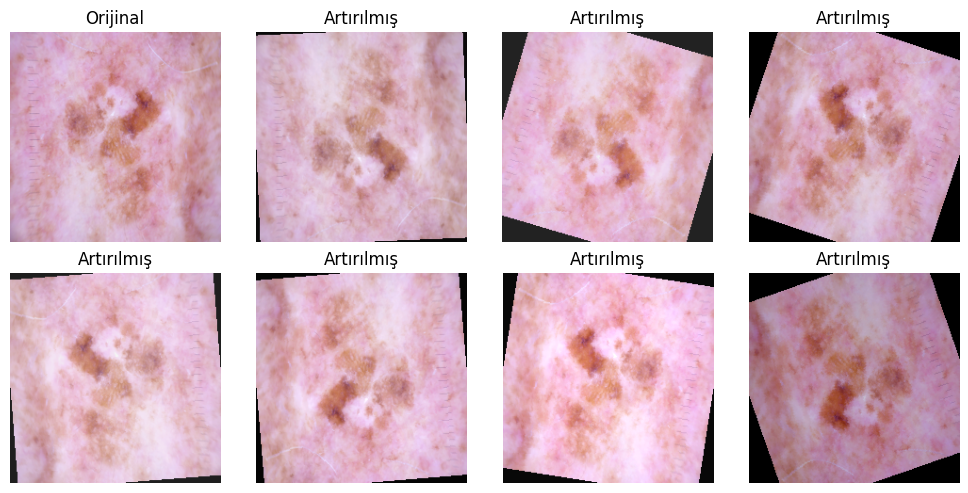

In [3]:
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms

aug = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.2, 0.2, 0.2),
])
ornek = Image.open(train_df.iloc[0]["path"]).convert("RGB")
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
axes[0, 0].imshow(ornek.resize((224, 224)))
axes[0, 0].set_title("Orijinal")
for ax in axes.flat[1:]:
    ax.imshow(aug(ornek))
    ax.set_title("Artırılmış")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig("augmentation.png", dpi=120)
plt.show()

In [4]:
# Deri Lezyonu — Deney A: AĞIRLIKSIZ kayıp (karşılaştırma için)
# Google Colab'da çalıştırmak için: Çalışma zamanı > Çalışma zamanı türünü değiştir > GPU
#
# 1) Kaggle'dan veri seti indirme (Colab hücresinde, başına ! koyarak):
#    !pip install -q kaggle
#    (kaggle.json dosyanı yükle: Kaggle > Settings > API > Create New Token)
#    !mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
#    !kaggle datasets download -d kmader/skin-cancer-mnist-ham10000
#    !unzip -q skin-cancer-mnist-ham10000.zip -d ham10000

import os, glob
import numpy as np
import pandas as pd
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

DATA_DIR = "ham10000"
IMG_SIZE = 224
BATCH = 32
EPOCHS = 10
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# ---------- 1. Meta veriyi oku ve ikili etikete çevir ----------
meta = pd.read_csv(os.path.join(DATA_DIR, "HAM10000_metadata.csv"))

# Kötü huylu: melanom (mel), bazal hücreli karsinom (bcc), aktinik keratoz (akiec)
MALIGNANT = {"mel", "bcc", "akiec"}
meta["label"] = meta["dx"].apply(lambda d: 1 if d in MALIGNANT else 0)

# Görsel dosya yollarını bul (iki klasöre bölünmüş durumda)
paths = {os.path.splitext(os.path.basename(p))[0]: p
         for p in glob.glob(os.path.join(DATA_DIR, "**", "*.jpg"), recursive=True)}
meta["path"] = meta["image_id"].map(paths)
meta = meta.dropna(subset=["path"])

print("Sınıf dağılımı:\n", meta["label"].value_counts())

# ---------- 2. Eğitim / doğrulama / test ayrımı ----------
# ÖNEMLİ: Aynı lezyonun birden fazla fotoğrafı var. lesion_id'ye göre ayırmazsak
# aynı lezyon hem eğitimde hem testte olur ve sonuçlar yapay olarak yüksek çıkar.
gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, temp_idx = next(gss.split(meta, groups=meta["lesion_id"]))
train_df, temp_df = meta.iloc[train_idx], meta.iloc[temp_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=42)
val_idx, test_idx = next(gss2.split(temp_df, groups=temp_df["lesion_id"]))
val_df, test_df = temp_df.iloc[val_idx], temp_df.iloc[test_idx]
print(f"Eğitim: {len(train_df)}  Doğrulama: {len(val_df)}  Test: {len(test_df)}")

# ---------- 3. Veri yükleyici ve veri artırma ----------
norm = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.2, 0.2, 0.2),
    transforms.ToTensor(), norm,
])
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), norm,
])

class LesionDS(Dataset):
    def __init__(self, df, tf):
        self.df, self.tf = df.reset_index(drop=True), tf
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        return self.tf(Image.open(r["path"]).convert("RGB")), int(r["label"])

train_dl = DataLoader(LesionDS(train_df, train_tf), BATCH, shuffle=True, num_workers=2)
val_dl   = DataLoader(LesionDS(val_df, eval_tf), BATCH, num_workers=2)
test_dl  = DataLoader(LesionDS(test_df, eval_tf), BATCH, num_workers=2)

# ---------- 4. Model: ImageNet ile önceden eğitilmiş MobileNetV2 ----------
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.last_channel, 2)
model = model.to(DEVICE)

# Sınıf dengesizliği: azınlık sınıfına (kötü huylu) daha yüksek ağırlık
counts = train_df["label"].value_counts().sort_index().values
weights = torch.tensor(counts.sum() / (2 * counts), dtype=torch.float32).to(DEVICE)
criterion = nn.CrossEntropyLoss()  # DENEY A: sınıf ağırlığı YOK
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# ---------- 5. Eğitim ve değerlendirme ----------
def evaluate(dl):
    model.eval()
    ys, probs = [], []
    with torch.no_grad():
        for x, y in dl:
            p = torch.softmax(model(x.to(DEVICE)), 1)[:, 1]
            probs += p.cpu().tolist(); ys += y.tolist()
    ys, probs = np.array(ys), np.array(probs)
    return ys, probs, (probs >= 0.5).astype(int)

best_auc = 0
for epoch in range(EPOCHS):
    model.train(); total = 0
    for x, y in train_dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward(); optimizer.step()
        total += loss.item() * len(y)
    ys, probs, _ = evaluate(val_dl)
    auc = roc_auc_score(ys, probs)
    print(f"Epoch {epoch+1}/{EPOCHS}  kayıp={total/len(train_df):.4f}  doğrulama AUC={auc:.4f}")
    if auc > best_auc:
        best_auc = auc
        torch.save(model.state_dict(), "agirliksiz_model.pt")

# ---------- 6. Test sonuçları (rapora girecek sayılar) ----------
model.load_state_dict(torch.load("agirliksiz_model.pt"))
ys, probs, preds = evaluate(test_dl)
print("\nTest AUC:", round(roc_auc_score(ys, probs), 4))
print(classification_report(ys, preds, target_names=["İyi huylu", "Kötü huylu"]))
print("Karmaşıklık matrisi:\n", confusion_matrix(ys, preds))

Sınıf dağılımı:
 label
0    8061
1    1954
Name: count, dtype: int64
Eğitim: 7002  Doğrulama: 1519  Test: 1494
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 60.8MB/s]


Epoch 1/10  kayıp=0.3680  doğrulama AUC=0.8851
Epoch 2/10  kayıp=0.2891  doğrulama AUC=0.8992
Epoch 3/10  kayıp=0.2647  doğrulama AUC=0.9091
Epoch 4/10  kayıp=0.2398  doğrulama AUC=0.9106
Epoch 5/10  kayıp=0.2197  doğrulama AUC=0.9103
Epoch 6/10  kayıp=0.2001  doğrulama AUC=0.9083
Epoch 7/10  kayıp=0.1890  doğrulama AUC=0.9047
Epoch 8/10  kayıp=0.1690  doğrulama AUC=0.9212
Epoch 9/10  kayıp=0.1584  doğrulama AUC=0.9236
Epoch 10/10  kayıp=0.1394  doğrulama AUC=0.9149

Test AUC: 0.9225
              precision    recall  f1-score   support

   İyi huylu       0.92      0.92      0.92      1176
  Kötü huylu       0.70      0.69      0.69       318

    accuracy                           0.87      1494
   macro avg       0.81      0.80      0.81      1494
weighted avg       0.87      0.87      0.87      1494

Karmaşıklık matrisi:
 [[1084   92]
 [ 100  218]]
